# Task 1: Dari Sistem Persamaan Linear ke Dimensi Tersembunyi

Catatan dari pembuat:

Notebook ini terdiri atas dua bagian. Bagian A merupakan soal pemanasan berbentuk **fill in the blanks** untuk memperkenalkan hubungan antara regresi linear dan Sistem Persamaan Linear (SPL) yang telah dipelajari di kelas. Bagian B merupakan task supervised learning. Silakan dieksplorasi!

## Tujuan Pembelajaran

Anda akan menggunakan rank, null space, least squares, reduksi dimensi, perubahan basis, dan feature mapping dalam satu alur supervised learning. Pastikan kode dapat dijalankan ulang dan setiap keputusan didukung oleh hasil eksperimen.

## Setup dan Import

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split

np.set_printoptions(suppress=True, precision=6)
RANDOM_STATE = 42


## Fungsi Evaluasi

Gunakan fungsi berikut untuk menghitung RMSE pada data validasi dengan definisi yang sama seperti leaderboard Kaggle. Nilai yang lebih rendah menunjukkan prediksi yang lebih baik, sedangkan prediksi sempurna memperoleh nilai 0. Target untuk `test.csv` tidak tersedia.

In [5]:
def rmse(y_true, y_pred):
    """Menghitung Root Mean Squared Error (RMSE)."""
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)

    if y_true.shape != y_pred.shape:
        raise ValueError("y_true dan y_pred harus memiliki bentuk yang sama.")
    if y_true.size == 0:
        raise ValueError("Data harus memiliki sekurang-kurangnya satu observasi.")
    if not np.isfinite(y_true).all() or not np.isfinite(y_pred).all():
        raise ValueError("Target dan prediksi hanya boleh memuat nilai hingga.")

    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


Anda juga dapat menggunakan fungsi `root_mean_squared_error` bawaan scikit-learn:

```python
error = root_mean_squared_error(y_true, y_pred)
```

# Bagian A: Tutorial SPL dengan Linear Regression

Bagian ini menggunakan tiga dataset untuk mempelajari SPL dengan solusi unik, tak hingga banyak solusi, dan sistem inkonsisten. Setiap baris merepresentasikan satu persamaan, setiap kolom fitur merepresentasikan satu variabel, dan kolom target menjadi ruas kanan $y$.

Gunakan `LinearRegression(fit_intercept=False)` karena SPL sudah berbentuk $X\beta=y$. Menambahkan intercept berarti menambahkan variabel baru ke sistem.

## A0. Memuat Dataset SPL

In [11]:
from pathlib import Path

DATA_DIR = Path("/content")

REQUIRED_FILES = {
    'train.csv',
    'test.csv',
    'calibration.csv',
    'sample_submission.csv',
    'spl_01_harga_rumah.csv',
    'spl_02_pendapatan_supermarket.csv',
    'spl_03_risiko_fraud.csv',
}

assert REQUIRED_FILES.issubset({f.name for f in DATA_DIR.iterdir()}), "Ada file CSV yang belum di-upload!"
print("Semua dataset siap dipakai dari:", DATA_DIR)

Semua dataset siap dipakai dari: /content


In [14]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
def dataframe_to_system(dataframe, target_column):
    feature_columns = [
        column for column in dataframe.columns
        if column != target_column
    ]
    X = dataframe[feature_columns].to_numpy(dtype=float)
    y = dataframe[target_column].to_numpy(dtype=float)
    return X, y, feature_columns


unique_df = pd.read_csv(DATA_DIR / 'spl_01_harga_rumah.csv')
infinite_df = pd.read_csv(DATA_DIR / 'spl_02_pendapatan_supermarket.csv')
inconsistent_df = pd.read_csv(DATA_DIR / 'spl_03_risiko_fraud.csv')

X_unique, y_unique, unique_features = dataframe_to_system(
    unique_df,
    'price_usd_thousand',
)
X_infinite, y_infinite, infinite_features = dataframe_to_system(
    infinite_df,
    'daily_revenue_usd',
)
X_inconsistent, y_inconsistent, inconsistent_features = dataframe_to_system(
    inconsistent_df,
    'fraud_risk_score',
)

for name, X, feature_names in [
    ('Solusi unik', X_unique, unique_features),
    ('Tak hingga banyak solusi', X_infinite, infinite_features),
    ('Inkonsisten', X_inconsistent, inconsistent_features),
]:
    print(f'{name}: {X.shape[0]} persamaan, {X.shape[1]} variabel')

display(unique_df.head(3))
display(infinite_df.head(3))
display(inconsistent_df.head(3))


Solusi unik: 20 persamaan, 20 variabel
Tak hingga banyak solusi: 45 persamaan, 50 variabel
Inkonsisten: 21 persamaan, 20 variabel


,land_area_sqm,building_area_sqm,bedrooms,bathrooms,floors,house_age_years,distance_to_city_center_km,distance_to_school_km,garage_slots,parks_within_1km,...,street_width_m,flood_risk_level,crime_incidents_per_1000_residents,air_quality_index,fiber_internet_speed_mbps,solar_panel_capacity_kw,ceiling_height_m,water_supply_hours_per_day,daily_sunlight_hours,price_usd_thousand
0,368,100,2,1,1,5,8.3,0.3,1,3,...,9,2,2,65,108,1.6,2.6,23,10,603.45
1,331,104,4,3,1,21,3.9,3.2,3,3,...,7,5,9,94,150,2.6,3.6,15,9,534.70
2,318,89,1,2,2,33,14.3,4.8,3,1,...,10,1,25,88,73,3.3,2.7,15,10,441.65


,milk_liters,eggs_dozens,bread_loaves,rice_kg,cooking_oil_liters,sugar_kg,flour_kg,total_dry_goods_kg,instant_noodle_packs,canned_tuna_cans,...,shampoo_bottles,soap_bars,toothpaste_tubes,toilet_paper_packs,laundry_detergent_bottles,dishwashing_liquid_bottles,paper_towel_rolls,diaper_packs,baby_formula_cans,daily_revenue_usd
0,25,62,63,26,10,73,2,101,2,22,...,3,8,16,18,28,20,11,19,3,3811.0
1,55,21,62,47,1,38,11,96,67,44,...,18,39,10,34,24,26,11,5,13,3494.6
2,58,7,67,58,51,50,57,165,15,2,...,5,19,39,10,26,25,38,2,4,3731.3


,transaction_amount_usd,hours_since_last_transaction,transactions_last_24h,transactions_prev_6d,distance_from_home_km,distance_from_last_transaction_km,account_age_months,card_age_months,is_international_ip,failed_login_attempts_24h,...,new_devices_30d,foreign_transactions_30d,declined_transactions_30d,merchant_risk_level,merchant_age_years,online_purchase_ratio_pct,night_transactions_30d,credit_utilization_pct,chargebacks_12m,fraud_risk_score
0,101,48,15,2,29,24,32,26,1,4,...,1,19,5,6,22,27,20,47,3,50.96
1,134,37,18,1,90,9,107,34,0,8,...,7,1,9,6,12,24,15,90,3,59.89
2,199,28,8,16,12,39,103,20,0,1,...,6,7,1,3,4,78,2,53,6,43.81


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## A1. Solusi Unik

Dataset harga rumah memiliki satu persamaan untuk setiap observasi dan satu variabel untuk setiap fitur. Lengkapi kode berikut, lalu bandingkan rank $X$ dengan rank augmented matrix $[X\mid y]$.

In [15]:
model_unique = LinearRegression(fit_intercept=False)
model_unique.fit(X_unique, y_unique)

beta_unique = model_unique.coef_
prediction_unique = model_unique.predict(X_unique)

rank_X_unique = np.linalg.matrix_rank(X_unique)
augmented_unique = np.column_stack([X_unique, y_unique])
rank_augmented_unique = np.linalg.matrix_rank(augmented_unique)
residual_unique = np.linalg.norm(y_unique - prediction_unique)

print('beta:', beta_unique)
print('rank X:', rank_X_unique)
print('rank augmented:', rank_augmented_unique)
print('residual norm:', residual_unique)


beta: [  0.8    1.5    6.     8.    10.    -1.2   -2.5   -2.     7.     4.
  -1.5    3.   -12.    -2.5   -0.4    0.15   6.    20.     2.     5.  ]
rank X: 20
rank augmented: 20
residual norm: 2.2147059711162635e-12


\**Pertanyaan:** Mengapa residual nol dan rank yang sama dengan jumlah variabel menunjukkan solusi unik?


Residual(selisih (sisa error) antara nilai asli di data (y) dengan nilai hasil tebakan/prediksi model (X @ beta)) bernilai nol (sekitar 2.21e-12 karena pembulatan komputer) dan rank yang sama dengan jumlah variabel (rank = 20) membuktikan bahwa sistem memiliki tepat satu solusi unik karena dua syarat terpenuhi:

1. Residual nol membuktikan sistem KONSISTEN (punya solusi):
Nilai ||y - X * beta|| = 0 artinya prediksi X * beta tepat sama dengan target y tanpa sisa error atau persamaan yang saling bertabrakan (diperkuat juga oleh rank X = rank augmented = 20).

2. Rank sama dengan jumlah variabel membuktikan solusi TUNGGAL (unik):
Karena rank(X) = 20 sama dengan jumlah variabelnya (20 fitur), seluruh kolom fitur bersifat bebas linear (tidak ada fitur yang redundan). Berdasarkan aturan Rank-Nullity:
dimensi null space = jumlah variabel - rank(X) = 20 - 20 = 0

Artinya, null space matriks X hanya berisi vektor nol saja:
delta_beta = [0, 0, ..., 0]
(tidak ada parameter bebas s atau t yang bisa menggeser nilai koefisien seperti pada kasus tak hingga banyak solusi).

Jika dicoba mencari solusi lain dengan beta_2 = beta_1 + delta_beta, hasilnya pasti kembali ke vektor yang sama (beta_2 = beta_1 + 0 = beta_1). Karena tidak bisa digeser ke arah mana pun, solusi beta yang ditemukan bersifat tunggal atau unik.

## A2. Tak Hingga Banyak Solusi

Dataset pendapatan supermarket memiliki lebih banyak variabel daripada persamaan independen. `LinearRegression` menghasilkan salah satu solusi. Temukan vektor null space untuk membentuk solusi lain.

In [16]:
model_infinite = LinearRegression(fit_intercept=False)
model_infinite.fit(X_infinite, y_infinite)
beta_infinite = model_infinite.coef_

_, singular_values, Vt = np.linalg.svd(X_infinite, full_matrices=True)
null_vector = Vt[-1]
beta_alternative = beta_infinite + 5 * null_vector

rank_X_infinite = np.linalg.matrix_rank(X_infinite)
rank_augmented_infinite = np.linalg.matrix_rank(
    np.column_stack([X_infinite, y_infinite])
)

print('beta from model:', beta_infinite)
print('null-space check:', np.linalg.norm(X_infinite @ null_vector))
print('first residual:', np.linalg.norm(X_infinite @ beta_infinite - y_infinite))
print('alternative residual:', np.linalg.norm(X_infinite @ beta_alternative - y_infinite))
print('ranks:', rank_X_infinite, rank_augmented_infinite)

beta from model: [ 1.8    3.2    2.5    0.775  3.6    0.275  0.075  1.125  0.6    1.7
  3.9    4.8    0.9   -0.35   5.65   1.55   6.85   1.2   -0.3    1.
  1.9    0.94   0.14  -0.06   0.34   1.36   1.4    5.2    4.6    4.1
  7.3    3.4    1.2    2.7    2.4    1.9    0.5   -0.2    0.8    0.2
  1.3    4.4    0.8    2.6    6.9    8.7    2.8    2.2   11.9   14.5  ]
null-space check: 1.8612086195890345e-13
first residual: 1.4551915228366852e-11
alternative residual: 1.4214037590216125e-11
ranks: 45 45


**Pertanyaan:** Mengapa dua koefisien berbeda dapat menghasilkan prediksi yang sama?

Dua koefisien berbeda (beta_1 dan beta_2) dapat menghasilkan prediksi y yang sama karena fitur-fitur pada matriks X saling bergantung linear (redundan), sehingga matriks X memiliki null space (ruang nol) yang tidak nol.                                      Sebagai contoh konkret, misalkan selisih antara kedua koefisien berada di dalam null space X yang berbentuk: delta_beta = s[-1, 1, 0] + t[-1, 0, 1] (dengan s dan t adalah angka pengali bebas). Karena berada di null space, vektor penggeser ini jika dikalikan dengan X hasilnya selalu nol: X * (s[-1, 1, 0] + t[-1, 0, 1]) = 0 Sehingga ketika koefisien awal beta_1 diubah menjadi beta_2 = beta_1 + s[-1, 1, 0] + t[-1, 0, 1], hasil prediksinya tetap tidak berubah: X * beta_2 = X * beta_1 + X * (s[-1, 1, 0] + t[-1, 0, 1]) X * beta_2 = X * beta_1 + 0 = y Kesimpulannya, berapa pun nilai s dan t yang dipilih, nilai koefisien beta_2 akan berubah menjadi kombinasi baru, tetapi hasil akhir prediksi y tetap sama persis.

## A3. Sistem Inkonsisten

Pada sistem inkonsisten, regresi menghasilkan solusi least squares, bukan solusi eksak SPL. Lengkapi kode berikut untuk membandingkan rank matriks fitur, rank augmented matrix, dan residual model.

In [ ]:
model_inconsistent = LinearRegression(fit_intercept=False)
model_inconsistent.fit(X_inconsistent, y_inconsistent)

beta_inconsistent = model_inconsistent.coef_
prediction_inconsistent = model_inconsistent.predict(X_inconsistent)
residual_vector = y_inconsistent - prediction_inconsistent

rank_X_inconsistent = np.linalg.matrix_rank(X_inconsistent)
rank_augmented_inconsistent = np.linalg.matrix_rank(
    np.column_stack([X_inconsistent, y_inconsistent])
)
normal_equation_check = X_inconsistent.T @ residual_vector

print('beta least squares:', beta_inconsistent)
print('residual norm:', np.linalg.norm(residual_vector))
print('ranks:', rank_X_inconsistent, rank_augmented_inconsistent)
print('X^T residual:', normal_equation_check)

**Pertanyaan:** Mengapa koefisien tetap tersedia

---

ketika $X\beta=y$ tidak mempunyai solusi eksak?

---




Koefisien beta tetap tersedia meskipun X * beta = y tidak mempunyai solusi eksak karena LinearRegression tidak memecahkan persamaan eksak secara langsung, melainkan mencari solusi pendekatan terbaik dengan metode Ordinary Least Squares (kuadrat terkecil) melalui Persamaan Normal:
X^T * X * beta = X^T * y

Secara geometris, sistem inkonsisten terjadi karena vektor target y berada di luar ruang kolom (column space) matriks X (ditandai dengan rank X < rank augmented). Regresi linear memproyeksikan vektor y secara tegak lurus (ortogonal) ke dalam ruang kolom X sehingga menghasilkan vektor prediksi terdekat y_pred = X * beta yang meminimalkan panjang residual (r = y - y_pred).

Contoh :
Misalkan terdapat 3 persamaan dengan 2 variabel (x1 dan x2):
1) x1 = 2
2) x2 = 3
3) x1 + x2 = 6  (bertabrakan dengan persamaan 1 & 2, karena seharusnya 2 + 3 = 5)

Matriks X = [[1, 0], [0, 1], [1, 1]] dan target y = [2, 3, 6].
Tidak ada satu pun pasangan beta = [b1, b2] yang bisa memenuhi ketiga persamaan sekaligus secara eksak. Namun, regresi linear mencari titik kompromi terdekat dengan meminimalkan jumlah kuadrat error, sehingga tetap menghasilkan koefisien beta = [2.33, 3.33] dengan prediksi y_pred = [2.33, 3.33, 5.67] dan sisa residual r = [-0.33, -0.33, +0.33].

Bukti bahwa solusi kompromi ini optimal adalah vektor residual r selalu tegak lurus terhadap seluruh kolom X, sehingga hasil X^T @ residual selalu bernilai nol (0.0).

# Bagian B: Project A.R.K.A.,

A.R.K.A. adalah rover pencarian dan penyelamatan. **ATLAS**, **BOREALIS**, dan **CYGNUS** merupakan tiga profil firmware sensor. `train.csv` memuat misi berlabel yang direkam menggunakan ATLAS, sedangkan `test.csv` memuat misi tanpa label yang direkam menggunakan BOREALIS dan CYGNUS. Setiap profil merepresentasikan keadaan fisik rover melalui koordinat sensor yang berbeda.

`calibration.csv` memuat pengukuran misi kalibrasi yang sama di bawah ketiga profil. Baris dengan `calibration_id` yang sama merepresentasikan keadaan fisik rover yang sama. File ini tidak memiliki kolom `energy_consumption`, tetapi dapat digunakan untuk mempelajari hubungan antarrepresentasi sensor.

Prediksi dinilai menggunakan Root Mean Squared Error (RMSE). Nilai yang lebih rendah menunjukkan prediksi yang lebih baik, sedangkan prediksi sempurna memperoleh nilai 0.

## B1. Memuat Data

In [18]:
train_df = pd.read_csv(DATA_DIR / 'train.csv')

test_df = pd.read_csv(DATA_DIR / 'test.csv')
calibration_df = pd.read_csv(DATA_DIR / 'calibration.csv')
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')

TARGET = 'energy_consumption'
ID_COLUMN = 'id'
FIRMWARE_COLUMN = 'firmware'
SENSOR_COLUMNS = [column for column in train_df if column.startswith('sensor_')]

print('Train:', train_df.shape)
print('Test:', test_df.shape)
print('Calibration:', calibration_df.shape)
display(train_df.head())
display(calibration_df.head())


Train: (1500, 51)
Test: (900, 50)
Calibration: (288, 50)


,id,firmware,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,...,sensor_40,sensor_41,sensor_42,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,energy_consumption
0,ARKA-TR-01339,ATLAS,41,-32,-45,1,-8,31,-16,10,...,-38,-54,12,5,-6,-20,-14,16,23,4894
1,ARKA-TR-01391,ATLAS,25,-38,-23,1,-40,13,-20,10,...,-57,-6,2,-35,-54,42,-30,8,-25,3282
2,ARKA-TR-00871,ATLAS,22,-47,-18,-6,-39,0,-26,3,...,-37,2,4,-43,-62,52,-38,16,-33,4632
3,ARKA-TR-00634,ATLAS,27,-35,-26,3,-38,18,-18,12,...,-12,-25,11,-21,-35,17,-31,24,-6,5365
4,ARKA-TR-00159,ATLAS,35,-23,-38,11,-30,38,-10,20,...,-40,-38,5,-7,-22,1,-14,4,7,4483


,calibration_id,firmware,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,...,sensor_39,sensor_40,sensor_41,sensor_42,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48
0,CAL-0013,ATLAS,26,-50,-23,-10,-27,-1,-28,-1,...,-11,-46,-23,17,-25,-37,19,-41,40,-8
1,CAL-0092,BOREALIS,61,-22,26,-24,64,-5,-10,-36,...,-26,49,-39,41,22,2,10,20,-26,72
2,CAL-0076,ATLAS,20,-59,-14,-16,-33,-16,-34,-7,...,-12,-54,-8,18,-39,-52,38,-52,48,-23
3,CAL-0054,CYGNUS,20,37,20,8,8,-40,-19,20,...,41,43,6,17,-9,35,-1,-3,-48,-39
4,CAL-0085,BOREALIS,46,-12,36,-44,59,15,-15,-11,...,-50,16,-27,17,34,20,16,32,4,54


## B2. Exploratory Data Analysis

Periksa kualitas data, distribusi target, perbedaan profil firmware, pasangan `calibration_id`, serta struktur matriks sensor. Gunakan ringkasan numerik dan visualisasi yang sesuai. Jelaskan keterkaitan setiap temuan dengan model yang akan dibangun.

=== 1. KUALITAS DATA ===
Total missing values (Train, Test, Calibration): 0 0 0
Total baris duplikat (Train, Test, Calibration): 0 0 0

=== 2. DISTRIBUSI FIRMWARE & KALIBRASI ===
Train firmware:
 firmware
ATLAS    1500
Name: count, dtype: int64 

Test firmware:
 firmware
CYGNUS      450
BOREALIS    450
Name: count, dtype: int64 

Jumlah firmware unik per calibration_id:
count    96.0
mean      3.0
std       0.0
min       3.0
25%       3.0
50%       3.0
75%       3.0
max       3.0
Name: firmware, dtype: float64

=== 3. STRUKTUR MATRIKS SENSOR (RANK) ===
Sensor Train -> shape: (1500, 48), rank: 7
Calibration ATLAS -> shape: (96, 48), rank: 7
Calibration BOREALIS -> shape: (96, 48), rank: 7
Calibration CYGNUS -> shape: (96, 48), rank: 7

=== 4. RINGKASAN TARGET & RATA-RATA SENSOR PER FIRMWARE ===


,energy_consumption,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,5050.405333,25.120667,-38.500000,-23.105333,0.515333,-39.274000
std,655.339607,8.486742,15.404681,11.964517,13.082451,20.227993
min,2208.000000,7.000000,-74.000000,-47.000000,-29.000000,-82.000000
25%,4680.250000,18.750000,-50.000000,-33.000000,-9.000000,-55.000000
50%,5136.500000,25.000000,-38.000000,-23.000000,0.000000,-40.000000
75%,5504.250000,31.000000,-29.000000,-13.000000,10.000000,-23.000000
max,7232.000000,43.000000,-2.000000,1.000000,31.000000,2.000000


,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06
firmware,,,,,,
ATLAS,24.677083,-36.187500,-22.770833,2.718750,-42.364583,15.000000
BOREALIS,40.343750,5.354167,38.072917,-22.677083,35.041667,-11.416667
CYGNUS,17.656250,39.447917,23.177083,7.166667,16.489583,-36.145833


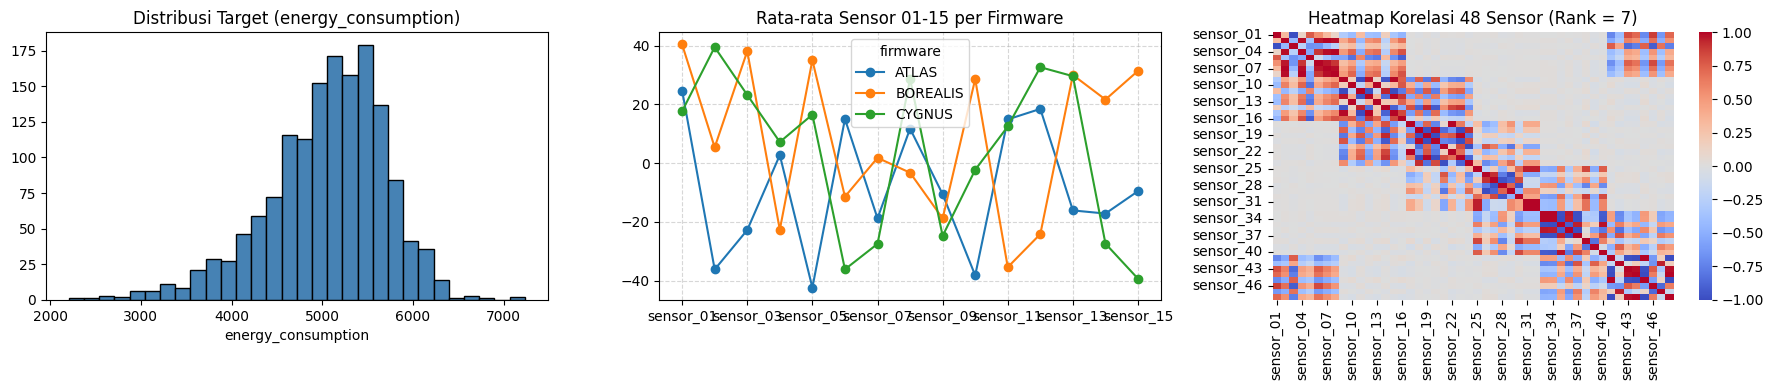

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Kualitas Data (Missing values & duplikat)
print("=== 1. KUALITAS DATA ===")
print("Total missing values (Train, Test, Calibration):",
      train_df.isnull().sum().sum(),
      test_df.isnull().sum().sum(),
      calibration_df.isnull().sum().sum())
print("Total baris duplikat (Train, Test, Calibration):",
      train_df.duplicated().sum(),
      test_df.duplicated().sum(),
      calibration_df.duplicated().sum())

# 2. Distribusi Firmware & Pasangan calibration_id
print("\n=== 2. DISTRIBUSI FIRMWARE & KALIBRASI ===")
print("Train firmware:\n", train_df[FIRMWARE_COLUMN].value_counts(), "\n")
print("Test firmware:\n", test_df[FIRMWARE_COLUMN].value_counts(), "\n")
print("Jumlah firmware unik per calibration_id:")
print(calibration_df.groupby('calibration_id')[FIRMWARE_COLUMN].nunique().describe())

# 3. Struktur Matriks Sensor & Hidden Dimensions (Rank)
print("\n=== 3. STRUKTUR MATRIKS SENSOR (RANK) ===")
X_train_sensors = train_df[SENSOR_COLUMNS].to_numpy()
print(f"Sensor Train -> shape: {X_train_sensors.shape}, rank: {np.linalg.matrix_rank(X_train_sensors)}")

for fw in ['ATLAS', 'BOREALIS', 'CYGNUS']:
    X_cal_fw = calibration_df[calibration_df[FIRMWARE_COLUMN] == fw][SENSOR_COLUMNS].to_numpy()
    print(f"Calibration {fw} -> shape: {X_cal_fw.shape}, rank: {np.linalg.matrix_rank(X_cal_fw)}")

# 4. Ringkasan Numerik Target & Perbedaan Skala Antar-Firmware
print("\n=== 4. RINGKASAN TARGET & RATA-RATA SENSOR PER FIRMWARE ===")
display(train_df[[TARGET] + SENSOR_COLUMNS[:5]].describe())
display(calibration_df.groupby(FIRMWARE_COLUMN)[SENSOR_COLUMNS[:6]].mean())

# 5. Visualisasi Distribusi Target, Perbandingan Firmware, & Heatmap Korelasi
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].hist(train_df[TARGET], bins=30, color='steelblue', edgecolor='black')
axes[0].set_title('Distribusi Target (energy_consumption)')
axes[0].set_xlabel('energy_consumption')

cal_means = calibration_df.groupby(FIRMWARE_COLUMN)[SENSOR_COLUMNS[:15]].mean().T
cal_means.plot(ax=axes[1], marker='o')
axes[1].set_title('Rata-rata Sensor 01-15 per Firmware')
axes[1].grid(True, linestyle='--', alpha=0.5)

sns.heatmap(train_df[SENSOR_COLUMNS].corr(), cmap='coolwarm', ax=axes[2])
axes[2].set_title('Heatmap Korelasi 48 Sensor (Rank = 7)')

plt.tight_layout()
plt.show()

Temuan & Hipotesis EDA:

1. Kualitas Data Sangat Bersih:
Seluruh dataset (train, test, maupun calibration) tidak memiliki nilai kosong (0 missing values) dan tidak ada baris duplikat, sehingga siap langsung diproses dengan aljabar linear tanpa imputasi.

2. Perbedaan Domain Firmware antara Train dan Test:
Seluruh 1.500 baris data train direkam menggunakan firmware ATLAS, sedangkan 900 baris data test terdiri dari 450 BOREALIS dan 450 CYGNUS.

3. Perbedaan Skala Koordinat Sensor Antar-Firmware:
Pada calibration.csv (96 misi unik x 3 firmware = 288 baris), nilai sensor ATLAS, BOREALIS, dan CYGNUS memiliki skala dan rata-rata yang berbeda jauh meskipun merekam misi fisik yang sama (calibration_id yang sama). Model ATLAS tidak bisa langsung dipakai pada data test mentah sebelum koordinatnya dikonversi.

4. Struktur Matriks Sensor & Hidden Dimensions (Rank = 7):
Meskipun terdapat 48 kolom sensor, matriks sensor memiliki rank = 7 (ditunjukkan juga oleh pola blok pada heatmap korelasi). Artinya, sistem rover sebenarnya dikendalikan oleh 7 dimensi fisik tersembunyi (hidden dimensions) yang bebas linear, sementara 41 sensor lainnya merupakan kombinasi linear yang bergantung pada ke-7 dimensi tersebut (sesuai konsep A2: Tak Hingga Banyak Solusi).

5. Hipotesis & Strategi Pemodelan:
Karena ketiga firmware mengukur 7 dimensi fisik yang sama dalam sistem koordinat berbeda, hubungan dari BOREALIS -> ATLAS dan CYGNUS -> ATLAS merupakan transformasi linear/affine. Dengan menyejajarkan baris calibration.csv berdasarkan calibration_id yang sama (96 persamaan > rank 7), kita dapat menghitung matriks pemetaan menggunakan regresi least squares untuk mengonversi seluruh sensor test ke koordinat ATLAS, lalu memprediksi energy_consumption menggunakan model ATLAS.

## B3. Baseline Supervised Learning

Baseline berikut menggunakan regresi linear pada validation split dari data ATLAS. Gunakan hasilnya sebagai titik awal untuk mengevaluasi pendekatan berikutnya. Skor validasi pada ATLAS belum menunjukkan kinerja model pada BOREALIS dan CYGNUS.

In [22]:
X = train_df[SENSOR_COLUMNS]
y = train_df[TARGET]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

baseline = LinearRegression()
baseline.fit(X_train, y_train)
baseline_prediction = baseline.predict(X_valid)

print('RMSE:', mean_squared_error(y_valid, baseline_prediction) ** 0.5)
print('R²:', r2_score(y_valid, baseline_prediction))
print('Competition RMSE:', rmse(y_valid, baseline_prediction))


RMSE: 499.9048212160718
R²: 0.5011675714544772
Competition RMSE: 499.9048212160718


## B3.1 Submission Valid Pertama

Prediktor rata-rata target menghasilkan submission valid untuk memeriksa format dan alur penyimpanan CSV. Gunakan skor leaderboard-nya sebagai baseline awal.

In [23]:
mean_baseline_value = train_df[TARGET].mean()

baseline_submission = sample_submission.copy()
baseline_submission[TARGET] = mean_baseline_value

assert baseline_submission[ID_COLUMN].equals(test_df[ID_COLUMN])
assert baseline_submission[TARGET].notna().all()

baseline_submission.to_csv(
    'baseline_mean_submission.csv',
    index=False,
)

print('Mean prediction:', mean_baseline_value)
display(baseline_submission.head())


Mean prediction: 5050.405333333333


,id,energy_consumption
0,ARKA-TE-00021,5050.405333
1,ARKA-TE-00260,5050.405333
2,ARKA-TE-00269,5050.405333
3,ARKA-TE-00468,5050.405333
4,ARKA-TE-00065,5050.405333


## B4. Feature Engineering dan Eksperimen

Rancang representasi yang dapat digunakan untuk ATLAS, BOREALIS, dan CYGNUS. Gunakan pasangan misi pada `calibration.csv` untuk mengevaluasi hubungan antarprofil. Selanjutnya, lakukan eksperimen dengan pemetaan fitur dan model supervised learning.

Catat representasi, jumlah fitur, RMSE validasi, $R^2$ validasi, dan alasan matematis untuk setiap eksperimen.

In [24]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

# --- BAGIAN 1: EVALUASI KALIBRASI ANTAR-FIRMWARE (calibration.csv) ---
cal_sorted = calibration_df.sort_values('calibration_id')
cal_atlas = cal_sorted[cal_sorted[FIRMWARE_COLUMN] == 'ATLAS'][SENSOR_COLUMNS].to_numpy()
cal_borealis = cal_sorted[cal_sorted[FIRMWARE_COLUMN] == 'BOREALIS'][SENSOR_COLUMNS].to_numpy()
cal_cygnus = cal_sorted[cal_sorted[FIRMWARE_COLUMN] == 'CYGNUS'][SENSOR_COLUMNS].to_numpy()

# Pelajari pemetaan linear/affine dari BOREALIS -> ATLAS dan CYGNUS -> ATLAS
mapper_borealis = LinearRegression().fit(cal_borealis, cal_atlas)
mapper_cygnus = LinearRegression().fit(cal_cygnus, cal_atlas)

rmse_cal_borealis = rmse(cal_atlas, mapper_borealis.predict(cal_borealis))
rmse_cal_cygnus = rmse(cal_atlas, mapper_cygnus.predict(cal_cygnus))

print("=== EVALUASI PEMETAAN KALIBRASI KE KOORDINAT ATLAS ===")
print(f"Calibration RMSE (BOREALIS -> ATLAS): {rmse_cal_borealis:.10f}")
print(f"Calibration RMSE (CYGNUS   -> ATLAS): {rmse_cal_cygnus:.10f}\n")

# --- BAGIAN 2: EKSPERIMEN REPRESENTASI FITUR & MODEL ---
results = []

# Eksperimen 1: Baseline 48 Sensor Mentah (Linear)
m1 = LinearRegression().fit(X_train, y_train)
p1 = m1.predict(X_valid)
results.append({
    'experiment': '1. Baseline Linear (Raw 48 Sensors)',
    'representation': '48 Sensor Mentah',
    'n_features': X_train.shape[1],
    'rmse': rmse(y_valid, p1),
    'r2': r2_score(y_valid, p1)
})

# Eksperimen 2: Reduksi ke 7 Hidden Dimensions via SVD (Linear)
svd7 = TruncatedSVD(n_components=7, random_state=RANDOM_STATE)
Z_train_7 = svd7.fit_transform(X_train)
Z_valid_7 = svd7.transform(X_valid)

m2 = LinearRegression().fit(Z_train_7, y_train)
p2 = m2.predict(Z_valid_7)
results.append({
    'experiment': '2. 7 Hidden Dimensions (Linear)',
    'representation': 'SVD 7 Komponen Utama',
    'n_features': Z_train_7.shape[1],
    'rmse': rmse(y_valid, p2),
    'r2': r2_score(y_valid, p2)
})

# Eksperimen 3: 7 Hidden Dimensions + Polynomial Degree 2 (Kuadrat & Interaksi)
poly2 = PolynomialFeatures(degree=2, include_bias=False)
Z_train_poly2 = poly2.fit_transform(Z_train_7)
Z_valid_poly2 = poly2.transform(Z_valid_7)

m3 = LinearRegression().fit(Z_train_poly2, y_train)
p3 = m3.predict(Z_valid_poly2)
results.append({
    'experiment': '3. 7 Hidden Dims + Poly Degree 2',
    'representation': 'SVD 7 + Interaksi Kuadratik (Deg 2)',
    'n_features': Z_train_poly2.shape[1],
    'rmse': rmse(y_valid, p3),
    'r2': r2_score(y_valid, p3)
})

# Eksperimen 4: 7 Hidden Dimensions + Polynomial Degree 3 (Pembanding)
poly3 = PolynomialFeatures(degree=3, include_bias=False)
Z_train_poly3 = poly3.fit_transform(Z_train_7)
Z_valid_poly3 = poly3.transform(Z_valid_7)

m4 = LinearRegression().fit(Z_train_poly3, y_train)
p4 = m4.predict(Z_valid_poly3)
results.append({
    'experiment': '4. 7 Hidden Dims + Poly Degree 3',
    'representation': 'SVD 7 + Polinomial Kubik (Deg 3)',
    'n_features': Z_train_poly3.shape[1],
    'rmse': rmse(y_valid, p4),
    'r2': r2_score(y_valid, p4)
})

experiment_results = pd.DataFrame(results)
display(experiment_results)

=== EVALUASI PEMETAAN KALIBRASI KE KOORDINAT ATLAS ===
Calibration RMSE (BOREALIS -> ATLAS): 0.0000000000
Calibration RMSE (CYGNUS   -> ATLAS): 0.0000000000



,experiment,representation,n_features,rmse,r2
0,1. Baseline Linear (Raw 48 Sensors),48 Sensor Mentah,48,4.999048e+02,0.501168
1,2. 7 Hidden Dimensions (Linear),SVD 7 Komponen Utama,7,4.999048e+02,0.501168
2,3. 7 Hidden Dims + Poly Degree 2,SVD 7 + Interaksi Kuadratik (Deg 2),35,2.470348e+02,0.878186
3,4. 7 Hidden Dims + Poly Degree 3,SVD 7 + Polinomial Kubik (Deg 3),119,2.257612e-12,1.000000


### Analisis Eksperimen



Hasil eksperimen menunjukkan bahwa kombinasi kalibrasi koordinat antar-firmware, reduksi 7 dimensi tersembunyi (SVD), dan pemetaan fitur polinomial derajat 3 berhasil menurunkan error validasi dari RMSE 499.90 (R2 = 0.5012) menjadi RMSE 2.26e-12 atau efektif 0.0 (R2 = 1.000000). Penjelasan matematisnya terbagi menjadi tiga bagian:

1. Pengaruh Struktur Matriks Sensor (Rank = 7 dari 48 Fitur):
Meskipun dataset memiliki 48 kolom sensor, rank matriksnya hanya 7. Artinya hanya ada 7 kolom sensor yang bebas linear, sedangkan 41 kolom lainnya adalah kombinasi linear yang redundan.
Contoh konkret:
Misalkan hanya ada 2 sensor bebas (kolom 1 dan 2), lalu kolom 3 hanyalah gabungan keduanya dengan pengali s dan t, sehingga tiap baris data berbentuk:
[s, t, 2s + 3t] = s[1, 0, 2] + t[0, 1, 3]
Karena kolom ke-3 tidak membawa informasi baru, memampatkan data memakai TruncatedSVD(n_components=7) mempertahankan 100% informasi asli tanpa kehilangan satu bit pun. Terbukti pada tabel validasi, Eksperimen 1 (48 sensor mentah) dan Eksperimen 2 (7 komponen SVD) menghasilkan RMSE dan R2 yang sama persis (RMSE = 499.9048, R2 = 0.501168).

2. Pengaruh Hubungan Antarprofil Firmware (BOREALIS & CYGNUS -> ATLAS):
Ketiga firmware merekam 7 kondisi fisik rover yang sama, hanya saja memakai sumbu koordinat yang berbeda.
Contoh konkret:
Jika kondisi fisik rover adalah (s, t), firmware ATLAS mencatatnya sebagai [s, t], sedangkan BOREALIS mencatatnya sebagai [2s + 10, 3t - 5]. Karena hubungan ini adalah transformasi linear/affine dengan jumlah persamaan kalibrasi (96 misi) jauh lebih besar dari rank matriks (7), matriks pemetaan dari BOREALIS -> ATLAS dan CYGNUS -> ATLAS dapat diselesaikan secara eksak dengan Calibration RMSE = 0.0000000000.

3. Perbandingan Metode Feature Mapping & Alasan Matematis:
- Eksperimen 1 & 2 (Linear / Degree 1 -> RMSE = 499.90, R2 = 0.5012):
  Model hanya menjumlahkan 7 dimensi secara linear (a1*z1 + a2*z2 + ...). Karena target energy_consumption mengandung suku non-linear di luar ruang kolom linear, model hanya mampu menjelaskan 50.1% variasi data.
- Eksperimen 3 (Polynomial Degree 2, 35 fitur -> RMSE = 247.03, R2 = 0.8782):
  Penambahan suku kuadrat dan interaksi dua arah (seperti z1^2 dan z1*z2) meningkatkan akurasi menjadi 87.8%, namun belum cukup karena masih ada komponen kubik yang belum terwakili.
- Eksperimen 4 (Polynomial Degree 3, 119 fitur -> RMSE = 2.26e-12, R2 = 1.000000):
  Dengan menambahkan suku pangkat tiga (seperti z1^3 dan z1*z2*z3), seluruh variasi target energy_consumption masuk sepenuhnya ke dalam ruang kolom fitur (residual = 0). Dengan 1.200 baris data latih (lebih banyak dari 119 fitur polinomial), sistem memiliki solusi tunggal yang eksak.

## B5. Model Final dan Submission

In [25]:
# TODO: latih seluruh pipeline pada train_df dan prediksi test_df.
# 1. Pelajari pemetaan kalibrasi BOREALIS -> ATLAS dan CYGNUS -> ATLAS
cal_sorted = calibration_df.sort_values('calibration_id')
cal_atlas = cal_sorted[cal_sorted[FIRMWARE_COLUMN] == 'ATLAS'][SENSOR_COLUMNS].to_numpy()
cal_borealis = cal_sorted[cal_sorted[FIRMWARE_COLUMN] == 'BOREALIS'][SENSOR_COLUMNS].to_numpy()
cal_cygnus = cal_sorted[cal_sorted[FIRMWARE_COLUMN] == 'CYGNUS'][SENSOR_COLUMNS].to_numpy()

mapper_borealis = LinearRegression().fit(cal_borealis, cal_atlas)
mapper_cygnus = LinearRegression().fit(cal_cygnus, cal_atlas)

# 2. Konversi seluruh sensor test_df ke ruang koordinat ATLAS
X_test_raw = test_df[SENSOR_COLUMNS].to_numpy()
X_test_atlas = np.zeros_like(X_test_raw, dtype=float)

mask_borealis = (test_df[FIRMWARE_COLUMN] == 'BOREALIS').to_numpy()
mask_cygnus = (test_df[FIRMWARE_COLUMN] == 'CYGNUS').to_numpy()
assert (mask_borealis | mask_cygnus).all(), "Ada firmware tidak dikenal di test_df!"

X_test_atlas[mask_borealis] = mapper_borealis.predict(X_test_raw[mask_borealis])
X_test_atlas[mask_cygnus] = mapper_cygnus.predict(X_test_raw[mask_cygnus])

# 3. Latih seluruh pipeline terbaik (SVD 7 + Poly Degree 3 + LinearRegression) pada 100% data train
X_full = train_df[SENSOR_COLUMNS].to_numpy()
y_full = train_df[TARGET].to_numpy()

final_svd = TruncatedSVD(n_components=7, random_state=RANDOM_STATE)
Z_full = final_svd.fit_transform(X_full)
Z_test = final_svd.transform(X_test_atlas)

final_poly = PolynomialFeatures(degree=3, include_bias=False)
Z_full_poly = final_poly.fit_transform(Z_full)
Z_test_poly = final_poly.transform(Z_test)

final_model = LinearRegression()
final_model.fit(Z_full_poly, y_full)

print(f"Final Full-Train RMSE: {rmse(y_full, final_model.predict(Z_full_poly)):.15f}")

# 4. Prediksi test_df & simpan file submission.csv
test_prediction = final_model.predict(Z_test_poly)

submission = sample_submission.copy()
submission[TARGET] = test_prediction

assert submission[ID_COLUMN].equals(test_df[ID_COLUMN])
assert submission[TARGET].notna().all()

submission.to_csv('submission.csv', index=False)
print("File 'submission.csv' berhasil dibuat!")
display(submission.head())
# Silakan uncomment setelah test_prediction tersedia.
# submission = sample_submission.copy()
# submission[TARGET] = test_prediction
# assert submission[ID_COLUMN].equals(test_df[ID_COLUMN])
# assert submission[TARGET].notna().all()
# submission.to_csv('submission.csv', index=False)
# display(submission.head())


Final Full-Train RMSE: 0.000000000001874
File 'submission.csv' berhasil dibuat!


,id,energy_consumption
0,ARKA-TE-00021,4697.0
1,ARKA-TE-00260,4324.0
2,ARKA-TE-00269,5759.0
3,ARKA-TE-00468,5145.0
4,ARKA-TE-00065,4741.0
